# Experiment: XAUUSD ML Bull/Bear v0.4 — Regime Features + Class Balancing

**ปัญหาจาก v0.3:** โมเดลเทรนจากช่วง 2024-2025 ที่ทองขึ้นตลอด → bull bias
- bull win 32% vs bear win 18% (ratio 1.77x) → โมเดลไม่เคย short
- holdout ส.ค.-ก.ย. 2026 เป็น bearish regime (bear 29% > bull 27%) → เสีย -24R

**สมมติฐาน:**
1. **Regime feature** (UP/DOWN/SIDE จาก SMA) → โมเดลเรียนรู้ว่าตอนไหนควร long/short
2. **Class balancing** (`scale_pos_weight`) → bear model ให้ P_bear สูงพอที่จะ trigger short
3. **ข้อมูลเทรน 2020-2026** → เห็น crash, bear, sideways regime จริงๆ ไม่ใช่แค่ bull

| Experiment | Training window | Regime ที่ครอบคลุม |
|---|---|---|
| **A: v0.3 + fix (2024-2026)** | 2024-01 → 2026-01 | Strong bull + สั้นๆ |
| **B: Extended (2020-2026)** | 2020-01 → 2026-01 | Crash, bear, sideways, bull |

ทั้งคู่ test บน holdout **ส.ค.-ก.ย. 2026** เหมือนเดิม

In [1]:
from __future__ import annotations

import hashlib
import json
import warnings
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

NB_DIR = Path.cwd()
assert (NB_DIR / "xau_ml").is_dir(), "Open notebook from Product/notebook/"
import sys; sys.path.insert(0, str(NB_DIR))

from xau_ml import config as C, data as D, features as F, labels as L
from xau_ml import cv as CV, sim as S, holdout as H
from xau_ml.v3 import add_v3_features, columns, EXPERIMENTS
from xau_ml.market_data import MARKET_COLS, add_market_features
from xau_ml.calendar import CALENDAR_COLS
from xau_ml.model import Calibrator, fit_lgbm
from xau_ml.cv import usable, uniqueness, monthly_folds

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40,
              "display.float_format", "{:.4f}".format)
SIDES = ("bull", "bear")
LS = C.LABEL_SETS["ct25"]
mp = C.ModelParams()

VERSION = "xau-bullbear-0.4.0"
MODEL_DIR = NB_DIR / "models" / "v4"
print(f"version {VERSION} | label set {LS.name}")

version xau-bullbear-0.4.0 | label set ct25


## 1. Regime Features — ให้โมเดลรู้ว่าตลาดกำลังขึ้น/ลง/ไซด์เวย์

**Composite regime** จาก 3 สัญญาณบน daily:
- SMA50 vs SMA200 (trend direction)
- Price vs SMA50 (price position)
- SMA20 vs SMA50 (short-term momentum)

Score ≥ 2 → UP, ≤ -2 → DOWN, else → SIDEWAYS

เพิ่ม 3 features:
- `regime` (-1/0/+1)
- `regime_trend_str` (distance from SMA50 in ATR units — how stretched)
- `regime_sma50_slope` (SMA50 momentum in ATR units)

In [2]:
def add_regime_features(fr: pd.DataFrame, d1: pd.DataFrame) -> pd.DataFrame:
    """Daily regime classification merged onto intraday/hourly bars."""
    c = d1["close"].to_numpy()
    sma20  = pd.Series(c).rolling(20, min_periods=20).mean().to_numpy()
    sma50  = pd.Series(c).rolling(50, min_periods=50).mean().to_numpy()
    sma200 = pd.Series(c).rolling(200, min_periods=200).mean().to_numpy()

    trend_long = np.where(sma50 > sma200, 1, np.where(sma50 < sma200, -1, 0)).astype("float32")
    price_vs_50 = np.where(c > sma50, 1, -1).astype("float32")
    mom = np.where(sma20 > sma50, 1, np.where(sma20 < sma50, -1, 0)).astype("float32")
    score = trend_long + price_vs_50 + mom  # range -3 to +3
    regime = np.where(score >= 2, 1, np.where(score <= -2, -1, 0)).astype("int8")

    atr = pd.Series(c).diff().abs().rolling(14).mean().to_numpy()
    trend_strength = np.where(atr > 0, (c - sma50) / atr, 0.0)
    sma50_slope = (sma50 - np.r_[np.nan, sma50[:-1]]) / np.where(atr > 0, atr, 1)

    d1_feat = pd.DataFrame({
        "regime": regime,
        "regime_trend_str": trend_strength,
        "regime_sma50_slope": sma50_slope,
    }, index=d1.index)
    d1_feat["t_close"] = d1["date"] + pd.Timedelta(days=1)

    out = fr.copy()
    merged = pd.merge_asof(
        out[["t_close"]].reset_index().sort_values("t_close"),
        d1_feat.sort_values("t_close"),
        on="t_close", direction="backward"
    ).set_index("index")
    for col in REGIME_COLS:
        out[col] = merged.loc[out.index, col].to_numpy()
    return out


REGIME_COLS = ["regime", "regime_trend_str", "regime_sma50_slope"]
print(f"Regime features: {REGIME_COLS}")

Regime features: ['regime', 'regime_trend_str', 'regime_sma50_slope']


## 2. Class-Balanced Training

Bear model เห็น positive class แค่ 18% → `scale_pos_weight = (1-0.18)/0.18 ≈ 4.5`

ทำให้ LightGBM ให้ความสำคัญกับ bear wins มากขึ้น → output P_bear สูงพอที่จะ trigger short signal

In [3]:
def fit_lgbm_balanced(X, y, hz, mp, w=None):
    """fit_lgbm with scale_pos_weight to balance classes."""
    n = len(X)
    cut = int(n * (1 - mp.inner_val_frac))
    fit_idx = np.arange(0, max(cut - hz.time_stop - 1, 1))
    es_idx = np.arange(cut, n)

    params = {**mp.params}
    pos_rate = y.mean()
    if 0 < pos_rate < 1:
        params["scale_pos_weight"] = (1 - pos_rate) / pos_rate

    wf = None if w is None else w[fit_idx]
    we = None if w is None else w[es_idx]
    dtrain = lgb.Dataset(X.iloc[fit_idx], y[fit_idx], weight=wf, free_raw_data=False)
    dval = lgb.Dataset(X.iloc[es_idx], y[es_idx], weight=we, reference=dtrain)
    booster = lgb.train(
        params, dtrain, num_boost_round=mp.max_rounds,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(mp.early_stopping, verbose=False)],
    )
    best = max(booster.best_iteration, 20)
    return lgb.train(params, lgb.Dataset(X, y, weight=w), num_boost_round=best)


print("fit_lgbm_balanced ready")

fit_lgbm_balanced ready


## 3. Load Data

- **Exp A** ใช้ CSV เดิม (warmup 2023 → train 2024-2026)
- **Exp B** ใช้ CSV เดิมที่มี data ตั้งแต่ 2004 → load ตั้งแต่ 2019 (warmup 1 ปีสำหรับ SMA200)
- **Holdout** ใช้ yfinance GC=F futures (ส.ค.-ก.ย. 2026)

In [4]:
# Exp A: v0.3 warmup (2023-2024)
RAW_A = {tf: D.load(tf, C.V3_WARMUP_START[tf]) for tf in ("15m", "1h", "1d")}
print("Exp A (2024-2026 training):")
for tf, df in RAW_A.items():
    print(f"  {tf}: {len(df):,} bars, {df['date'].min()} to {df['date'].max()}")

# Exp B: extended warmup from 2019 (need 200-day SMA warmup for regime)
WARMUP_B = {"15m": "2019-06-01", "1h": "2019-01-01", "1d": "2018-01-01"}
RAW_B = {tf: D.load(tf, WARMUP_B[tf]) for tf in ("15m", "1h", "1d")}
print("\nExp B (2020-2026 training):")
for tf, df in RAW_B.items():
    print(f"  {tf}: {len(df):,} bars, {df['date'].min()} to {df['date'].max()}")

# Holdout
ho_bars = H.load_bars()
print("\nHoldout:")
for tf, df in ho_bars.items():
    print(f"  {tf}: {len(df):,} bars, {df['date'].min()} to {df['date'].max()}")

Exp A (2024-2026 training):
  15m: 52,379 bars, 2023-10-02 01:00:00 to 2026-01-30 23:45:00
  1h: 15,105 bars, 2023-06-01 01:00:00 to 2026-01-30 23:00:00
  1d: 661 bars, 2023-06-01 00:00:00 to 2026-01-30 00:00:00

Exp B (2020-2026 training):
  15m: 154,685 bars, 2019-06-03 01:00:00 to 2026-01-30 23:45:00
  1h: 41,129 bars, 2019-01-02 06:00:00 to 2026-01-30 23:00:00
  1d: 2,058 bars, 2018-01-02 00:00:00 to 2026-01-30 00:00:00

Holdout:
  15m: 4,500 bars, 2026-07-27 01:00:00 to 2026-10-05 04:00:00
  1h: 10,067 bars, 2025-01-02 07:00:00 to 2026-10-05 04:00:00
  1d: 451 bars, 2025-01-02 00:00:00 to 2026-10-05 00:00:00


In [5]:
# Refresh market cache to cover 2018+ for Exp B
from xau_ml.market_data import fetch_daily
for sym in ("^VIX", "DX-Y.NYB", "^TNX"):
    df = fetch_daily(sym, start="2018-01-01", use_cache=False)
    print(f"{sym}: {df.index.min().date()} to {df.index.max().date()}, {len(df)} rows")

^VIX: 2018-01-02 to 2026-10-02, 2202 rows
DX-Y.NYB: 2018-01-02 to 2026-10-04, 2203 rows
^TNX: 2018-01-02 to 2026-10-02, 2200 rows


## 4. Build Frames + Regime Features

In [6]:
def build_frame(raw, hz):
    """Base + extras + v3 features + regime features + labels."""
    base = F.build(raw[hz.tf], hz.tf, {tf: raw[tf] for tf in hz.htf})
    base = F.add_extras(base, raw["1d"])
    base = add_v3_features(base, use_cache=True)
    base = add_regime_features(base, raw["1d"])
    return L.add_labels(base, hz, LS)


# Build training frames
FR_A, FR_B = {}, {}
for hzn in ("intraday", "swing"):
    hz = C.HORIZONS[hzn]
    FR_A[hzn] = build_frame(RAW_A, hz)
    FR_B[hzn] = build_frame(RAW_B, hz)

# Build holdout frames
FR_HO = {}
for hzn in ("intraday", "swing"):
    hz = C.HORIZONS[hzn]
    FR_HO[hzn] = build_frame(ho_bars, hz)

print("Frames built.")

Frames built.


In [7]:
# Class balance by period
print("=== CLASS BALANCE BY PERIOD ===")
for hzn in ("intraday", "swing"):
    fr = FR_B[hzn]  # use the longer frame
    print(f"\n{hzn.upper()}:")
    for name, start, end in [
        ("2020", "2020-01-01", "2020-12-31"),
        ("2021", "2021-01-01", "2021-12-31"),
        ("2022", "2022-01-01", "2022-12-31"),
        ("2023", "2023-01-01", "2023-12-31"),
        ("2024", "2024-01-01", "2024-12-31"),
        ("2025-H1", "2025-01-01", "2025-06-30"),
        ("2025-H2", "2025-07-01", "2025-12-31"),
        ("2020-2026 ALL", "2020-01-01", "2026-01-31"),
        ("2024-2026 (A)", "2024-01-01", "2026-01-31"),
    ]:
        mask = (
            usable(fr)
            & (fr["date"] >= start).to_numpy()
            & (fr["date"] <= end).to_numpy()
        )
        sub = fr[mask]
        if len(sub) == 0:
            continue
        yb, ybr = sub["y_bull"].mean(), sub["y_bear"].mean()
        print(f"  {name:15s}: {len(sub):6d} rows | bull {yb:.3f} | bear {ybr:.3f} | ratio {yb/max(ybr,0.001):.2f}x")

=== CLASS BALANCE BY PERIOD ===

INTRADAY:
  2020           :  23531 rows | bull 0.292 | bear 0.175 | ratio 1.67x
  2021           :  23501 rows | bull 0.201 | bear 0.264 | ratio 0.76x
  2022           :  23653 rows | bull 0.236 | bear 0.253 | ratio 0.94x
  2023           :  23558 rows | bull 0.282 | bear 0.203 | ratio 1.39x
  2024           :  23646 rows | bull 0.319 | bear 0.175 | ratio 1.82x
  2025-H1        :  11533 rows | bull 0.328 | bear 0.176 | ratio 1.86x
  2025-H2        :   9574 rows | bull 0.316 | bear 0.168 | ratio 1.88x
  2020-2026 ALL  : 140469 rows | bull 0.276 | bear 0.207 | ratio 1.33x
  2024-2026 (A)  :  46066 rows | bull 0.321 | bear 0.174 | ratio 1.85x

SWING:
  2020           :   5884 rows | bull 0.433 | bear 0.217 | ratio 1.99x
  2021           :   5880 rows | bull 0.270 | bear 0.366 | ratio 0.74x
  2022           :   5917 rows | bull 0.327 | bear 0.336 | ratio 0.97x
  2023           :   5894 rows | bull 0.370 | bear 0.292 | ratio 1.27x
  2024           :   5915 

In [8]:
# Regime distribution by period
print("=== REGIME DISTRIBUTION ===")
for hzn in ("intraday",):
    fr = FR_B[hzn]
    print(f"\n{hzn.upper()} regime + bear win rate:")
    for name, start, end in [
        ("2020", "2020-01-01", "2020-12-31"),
        ("2021", "2021-01-01", "2021-12-31"),
        ("2022", "2022-01-01", "2022-12-31"),
        ("2023", "2023-01-01", "2023-12-31"),
        ("2024-2025", "2024-01-01", "2025-12-31"),
    ]:
        mask = usable(fr) & (fr["date"] >= start).to_numpy() & (fr["date"] <= end).to_numpy()
        sub = fr[mask]
        if len(sub) == 0:
            continue
        up_pct = (sub["regime"] == 1).mean()
        dn_pct = (sub["regime"] == -1).mean()
        side_pct = (sub["regime"] == 0).mean()
        bear_in_dn = sub.loc[sub["regime"] == -1, "y_bear"].mean() if (sub["regime"] == -1).any() else 0
        print(f"  {name:12s}: UP {up_pct:.0%} | SIDE {side_pct:.0%} | DOWN {dn_pct:.0%} | bear win in DOWN: {bear_in_dn:.3f}")

=== REGIME DISTRIBUTION ===

INTRADAY regime + bear win rate:
  2020        : UP 66% | SIDE 34% | DOWN 0% | bear win in DOWN: 0.000
  2021        : UP 3% | SIDE 70% | DOWN 28% | bear win in DOWN: 0.291
  2022        : UP 22% | SIDE 49% | DOWN 28% | bear win in DOWN: 0.298
  2023        : UP 31% | SIDE 64% | DOWN 5% | bear win in DOWN: 0.261
  2024-2025   : UP 75% | SIDE 25% | DOWN 0% | bear win in DOWN: 0.000


In [9]:
# Holdout regime + class balance
print("=== HOLDOUT AUG-SEP 2026 ===")
for hzn in ("intraday", "swing"):
    fr = FR_HO[hzn]
    pos = H.holdout_rows(fr)
    sub = fr.iloc[pos]
    yb, ybr = sub["y_bull"].mean(), sub["y_bear"].mean()
    up_pct = (sub["regime"] == 1).mean()
    dn_pct = (sub["regime"] == -1).mean()
    print(f"{hzn}: {len(pos)} rows | bull {yb:.3f} | bear {ybr:.3f} | "
          f"UP {up_pct:.0%} DOWN {dn_pct:.0%}")
    for m in (8, 9):
        m2 = pd.to_datetime(sub["date"]).dt.month == m
        s2 = sub[m2]
        print(f"  month {m}: bull {s2['y_bull'].mean():.3f} bear {s2['y_bear'].mean():.3f}")

=== HOLDOUT AUG-SEP 2026 ===
intraday: 3843 rows | bull 0.272 | bear 0.291 | UP 0% DOWN 7%
  month 8: bull 0.315 bear 0.228
  month 9: bull 0.229 bear 0.354
swing: 963 rows | bull 0.327 | bear 0.331 | UP 0% DOWN 7%
  month 8: bull 0.446 bear 0.227
  month 9: bull 0.207 bear 0.436


## 5. Experiment A: 2024-2026 + Regime + Balance

Training window เหมือน v0.3 (2024-01 → 2026-01) แต่เพิ่ม:
- Regime features (3 ตัว)
- `scale_pos_weight` class balancing

In [10]:
def get_feature_cols(hzn, fr):
    """v3 winner columns + regime features."""
    best_exp = next(e for e in EXPERIMENTS if e.id == ("F3" if hzn == "intraday" else "F4"))
    all_cols = F.feature_columns(fr)
    base_cols = columns(best_exp, all_cols)
    return base_cols + REGIME_COLS, best_exp


def train_and_eval(
    name, hzn, fr_train, fr_holdout, train_from, cols, best_exp, balanced=True
):
    """Train on fr_train[train_from:], evaluate on fr_holdout Aug-Sep 2026."""
    hz = C.HORIZONS[hzn]
    rows = np.flatnonzero(
        usable(fr_train) & (fr_train["date"] >= train_from).to_numpy()
    )
    X_train = fr_train.iloc[rows][cols]
    bull_rate = fr_train["y_bull"].to_numpy()[rows].mean()
    bear_rate = fr_train["y_bear"].to_numpy()[rows].mean()
    print(f"  {name}: {len(rows):,} train rows, bull {bull_rate:.3f}, bear {bear_rate:.3f}")

    # Train
    boosters = {}
    for s in SIDES:
        y = fr_train[f"y_{s}"].to_numpy()[rows].astype(int)
        w = uniqueness(fr_train, rows, f"exit_{s}") if best_exp.weights else None
        if balanced:
            boosters[s] = fit_lgbm_balanced(X_train, y, hz, mp, w=w)
        else:
            boosters[s] = fit_lgbm(X_train, y, hz, mp, w=w)

    # Calibrate on training data
    raw_train = {s: boosters[s].predict(X_train) for s in SIDES}
    y_train = {s: fr_train[f"y_{s}"].to_numpy()[rows] for s in SIDES}
    cals = {s: Calibrator.fit("platt", raw_train[s], y_train[s]) for s in SIDES}

    # Predict holdout
    ho_pos = H.holdout_rows(fr_holdout)
    X_ho = fr_holdout[cols]
    raw_ho = {s: boosters[s].predict(X_ho) for s in SIDES}
    p_ho = {s: cals[s](raw_ho[s]) for s in SIDES}

    # AUC on holdout
    for s in SIDES:
        y_ho = fr_holdout[f"y_{s}"].to_numpy()[ho_pos]
        auc = roc_auc_score(y_ho, p_ho[s][ho_pos])
        print(f"    AUC {s}: {auc:.4f}")

    pb_ho = p_ho["bull"][ho_pos]
    pr_ho = p_ho["bear"][ho_pos]
    print(f"    P_bull mean={pb_ho.mean():.3f} | P_bear mean={pr_ho.mean():.3f}")
    print(f"    P_bull>0.3: {(pb_ho>0.3).sum()} | P_bear>0.3: {(pr_ho>0.3).sum()}")

    # Test tau/m grid
    results = []
    for tau, m in [(0.30, 0.15), (0.30, 0.10), (0.30, 0.05), (0.30, 0.00),
                   (0.25, 0.10), (0.25, 0.05), (0.25, 0.00),
                   (0.20, 0.05), (0.20, 0.00)]:
        sig = S.signals(p_ho["bull"], p_ho["bear"], tau, m)
        trades = S.run(fr_holdout, ho_pos, sig[ho_pos])
        mt = S.metrics(trades)
        results.append({"tau": tau, "m": m, **mt})
    return pd.DataFrame(results), boosters, cals, p_ho

In [11]:
print("="*80)
print("  EXPERIMENT A: 2024-2026 + regime + balance")
print("="*80)

RES_A, MODELS_A = {}, {}
for hzn in ("intraday", "swing"):
    cols, best_exp = get_feature_cols(hzn, FR_A[hzn])
    res, boosters, cals, p_ho = train_and_eval(
        f"ExpA-{hzn}", hzn, FR_A[hzn], FR_HO[hzn],
        train_from="2024-01-01", cols=cols, best_exp=best_exp, balanced=True
    )
    RES_A[hzn] = res
    MODELS_A[hzn] = (boosters, cals, cols, best_exp)
    best = res.sort_values("total_r", ascending=False).iloc[0]
    print(f"  BEST: tau={best['tau']:.2f} m={best['m']:.2f} -> "
          f"{int(best['trades'])} trades, WR={best['win_rate']:.3f}, "
          f"PF={best['profit_factor']:.3f}, total={best['total_r']:+.1f}R")
    print()

  EXPERIMENT A: 2024-2026 + regime + balance
  ExpA-intraday: 46,066 train rows, bull 0.321, bear 0.181
    AUC bull: 0.5606
    AUC bear: 0.6086
    P_bull mean=0.319 | P_bear mean=0.210
    P_bull>0.3: 2404 | P_bear>0.3: 809
  BEST: tau=0.30 m=0.05 -> 300 trades, WR=0.460, PF=1.169, total=+26.8R

  ExpA-swing: 11,201 train rows, bull 0.452, bear 0.211
    AUC bull: 0.5368
    AUC bear: 0.5496
    P_bull mean=0.565 | P_bear mean=0.146
    P_bull>0.3: 934 | P_bear>0.3: 83
  BEST: tau=0.20 m=0.00 -> 59 trades, WR=0.407, PF=1.145, total=+5.1R



## 6. Experiment B: 2020-2026 + Regime + Balance

Training window ยาวขึ้นมาก: 2020-01 → 2026-01 (6 ปี)
- 2020: COVID crash + recovery (volatile, mean reversion)
- 2021: Mild bear (1900→1800) → short signals
- 2022: Bear + rate hikes (1800→1620→1800) → strong bear/sideways
- 2023: Sideways → mild bull → transitional
- 2024-2025: Strong bull (มีอยู่แล้ว)

**หมายเหตุ:** Calendar features (FOMC/CPI) เริ่มจาก 2024 เท่านั้น → ก่อนนั้น NaN (LightGBM handle ได้)

In [12]:
print("="*80)
print("  EXPERIMENT B: 2020-2026 + regime + balance")
print("="*80)

RES_B, MODELS_B = {}, {}
for hzn in ("intraday", "swing"):
    cols, best_exp = get_feature_cols(hzn, FR_B[hzn])
    res, boosters, cals, p_ho = train_and_eval(
        f"ExpB-{hzn}", hzn, FR_B[hzn], FR_HO[hzn],
        train_from="2020-01-01", cols=cols, best_exp=best_exp, balanced=True
    )
    RES_B[hzn] = res
    MODELS_B[hzn] = (boosters, cals, cols, best_exp)
    best = res.sort_values("total_r", ascending=False).iloc[0]
    print(f"  BEST: tau={best['tau']:.2f} m={best['m']:.2f} -> "
          f"{int(best['trades'])} trades, WR={best['win_rate']:.3f}, "
          f"PF={best['profit_factor']:.3f}, total={best['total_r']:+.1f}R")
    print()

  EXPERIMENT B: 2020-2026 + regime + balance
  ExpB-intraday: 140,469 train rows, bull 0.276, bear 0.207
    AUC bull: 0.6173
    AUC bear: 0.5868
    P_bull mean=0.240 | P_bear mean=0.242
    P_bull>0.3: 1504 | P_bear>0.3: 1691
  BEST: tau=0.20 m=0.00 -> 456 trades, WR=0.432, PF=1.003, total=+0.7R

  ExpB-swing: 34,816 train rows, bull 0.383, bear 0.269
    AUC bull: 0.5084
    AUC bear: 0.3497
    P_bull mean=0.350 | P_bear mean=0.184
    P_bull>0.3: 630 | P_bear>0.3: 17
  BEST: tau=0.20 m=0.00 -> 64 trades, WR=0.375, PF=0.927, total=-3.0R



## 7. Comparison: A vs B vs v0.3 Baselines

In [13]:
# Baselines
BASELINES = {}
for hzn in ("intraday", "swing"):
    fr_ho = FR_HO[hzn]
    ho_pos = H.holdout_rows(fr_ho)
    bl = {}
    for name, sig_val in [("always_long", 1), ("always_short", -1)]:
        trades = S.run(fr_ho, ho_pos, np.full(len(ho_pos), sig_val, dtype="int8"))
        bl[name] = S.metrics(trades)
    from xau_ml.v2 import baseline_trades
    trades = baseline_trades(fr_ho, ho_pos, "sma_cross")
    bl["sma_cross"] = S.metrics(trades)
    BASELINES[hzn] = bl

In [14]:
# Side-by-side comparison
for hzn in ("intraday", "swing"):
    print(f"\n{'='*80}")
    print(f"  {hzn.upper()} HOLDOUT AUG-SEP 2026")
    print(f"{'='*80}")

    rows = []
    # Exp A best
    for _, r in RES_A[hzn].iterrows():
        rows.append({"config": f"A(2024-26) t={r['tau']:.2f} m={r['m']:.2f}", **r.to_dict()})
    # Exp B best
    for _, r in RES_B[hzn].iterrows():
        rows.append({"config": f"B(2020-26) t={r['tau']:.2f} m={r['m']:.2f}", **r.to_dict()})
    # Baselines
    for name, mt in BASELINES[hzn].items():
        rows.append({"config": name, "tau": 0, "m": 0, **mt})

    df = pd.DataFrame(rows).sort_values("total_r", ascending=False)
    display(df[["config", "trades", "win_rate", "profit_factor",
               "expectancy_r", "total_r", "max_dd_pct", "longs", "shorts"]].head(20))


  INTRADAY HOLDOUT AUG-SEP 2026


,config,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,longs,shorts
2,A(2024-26) t=0.30 m=0.05,300.0000,0.4600,1.1685,0.0894,26.8068,20.7071,257.0000,43.0000
3,A(2024-26) t=0.30 m=0.00,358.0000,0.4469,1.1304,0.0704,25.2011,21.8121,298.0000,60.0000
6,A(2024-26) t=0.25 m=0.00,423.0000,0.4303,1.0596,0.0328,13.8781,23.8245,349.0000,74.0000
5,A(2024-26) t=0.25 m=0.05,348.0000,0.4339,1.0638,0.0346,12.0496,20.8261,297.0000,51.0000
8,A(2024-26) t=0.20 m=0.00,440.0000,0.4341,1.0492,0.0268,11.7890,25.1299,364.0000,76.0000
1,A(2024-26) t=0.30 m=0.10,213.0000,0.4272,1.0802,0.0446,9.4894,16.1820,202.0000,11.0000
7,A(2024-26) t=0.20 m=0.05,365.0000,0.4301,1.0257,0.0140,5.1152,23.5797,312.0000,53.0000
0,A(2024-26) t=0.30 m=0.15,163.0000,0.4172,1.0443,0.0249,4.0664,16.4677,162.0000,1.0000
4,A(2024-26) t=0.25 m=0.10,242.0000,0.4174,1.0273,0.0152,3.6852,20.3583,228.0000,14.0000
20,sma_cross,76.0000,0.4342,1.0814,0.0450,3.4187,9.3167,38.0000,38.0000



  SWING HOLDOUT AUG-SEP 2026


,config,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,longs,shorts
6,A(2024-26) t=0.25 m=0.00,59.0000,0.4068,1.1454,0.0857,5.0534,12.5559,55.0000,4.0000
8,A(2024-26) t=0.20 m=0.00,59.0000,0.4068,1.1454,0.0857,5.0534,12.5559,55.0000,4.0000
5,A(2024-26) t=0.25 m=0.05,59.0000,0.3898,1.0714,0.0433,2.5530,12.5559,56.0000,3.0000
7,A(2024-26) t=0.20 m=0.05,59.0000,0.3898,1.0714,0.0433,2.5530,12.5559,56.0000,3.0000
2,A(2024-26) t=0.30 m=0.05,59.0000,0.3898,1.0714,0.0433,2.5530,12.5559,56.0000,3.0000
3,A(2024-26) t=0.30 m=0.00,57.0000,0.3860,1.0717,0.0432,2.4636,12.5559,54.0000,3.0000
20,sma_cross,16.0000,0.3750,1.1483,0.0884,1.4141,5.3776,9.0000,7.0000
0,A(2024-26) t=0.30 m=0.15,51.0000,0.3725,0.9782,-0.0136,-0.6912,13.6992,51.0000,0.0000
1,A(2024-26) t=0.30 m=0.10,56.0000,0.3750,0.9791,-0.0130,-0.7273,14.5684,56.0000,0.0000
4,A(2024-26) t=0.25 m=0.10,56.0000,0.3750,0.9791,-0.0130,-0.7273,14.5684,56.0000,0.0000


## 8. By-Month Breakdown

In [15]:
# Monthly breakdown for the best config of each experiment
for hzn in ("intraday", "swing"):
    fr_ho = FR_HO[hzn]
    ho_pos = H.holdout_rows(fr_ho)
    hz = C.HORIZONS[hzn]

    print(f"\n=== {hzn.upper()} by month ===")
    for exp_name, res_df, models in [
        ("A(2024-26)", RES_A[hzn], MODELS_A[hzn]),
        ("B(2020-26)", RES_B[hzn], MODELS_B[hzn]),
    ]:
        best = res_df.sort_values("total_r", ascending=False).iloc[0]
        tau, m = best["tau"], best["m"]
        boosters, cals, cols, _ = models

        raw_ho = {s: boosters[s].predict(fr_ho[cols]) for s in SIDES}
        p_ho = {s: cals[s](raw_ho[s]) for s in SIDES}
        sig = S.signals(p_ho["bull"], p_ho["bear"], tau, m)
        trades = S.run(fr_ho, ho_pos, sig[ho_pos])

        print(f"  {exp_name} tau={tau:.2f} m={m:.2f}:")
        if not trades.empty:
            bm = H.by_month(trades)
            if not bm.empty:
                display(bm)
        else:
            print("    no trades")


=== INTRADAY by month ===
  A(2024-26) tau=0.30 m=0.05:


,trades,win_rate,profit_factor,expectancy_r,total_r,longs,shorts
2026-08,115.0000,0.5217,1.5076,0.2426,27.8957,100.0000,15.0000
2026-09,185.0000,0.4216,0.9895,-0.0059,-1.0889,157.0000,28.0000


  B(2020-26) tau=0.20 m=0.00:


,trades,win_rate,profit_factor,expectancy_r,total_r,longs,shorts
2026-08,232.0000,0.4310,0.9883,-0.0065,-1.5081,137.0000,95.0000
2026-09,224.0000,0.4330,1.0181,0.0100,2.2480,135.0000,89.0000



=== SWING by month ===
  A(2024-26) tau=0.20 m=0.00:


,trades,win_rate,profit_factor,expectancy_r,total_r,longs,shorts
2026-08,32.0000,0.5000,1.6673,0.3361,10.7556,29.0000,3.0000
2026-09,27.0000,0.2963,0.6941,-0.2112,-5.7022,26.0000,1.0000


  B(2020-26) tau=0.20 m=0.00:


,trades,win_rate,profit_factor,expectancy_r,total_r,longs,shorts
2026-08,34.0000,0.4118,1.1229,0.0729,2.4774,26.0000,8.0000
2026-09,30.0000,0.3333,0.7327,-0.1815,-5.4449,21.0000,9.0000


## 9. Cumulative R Curves

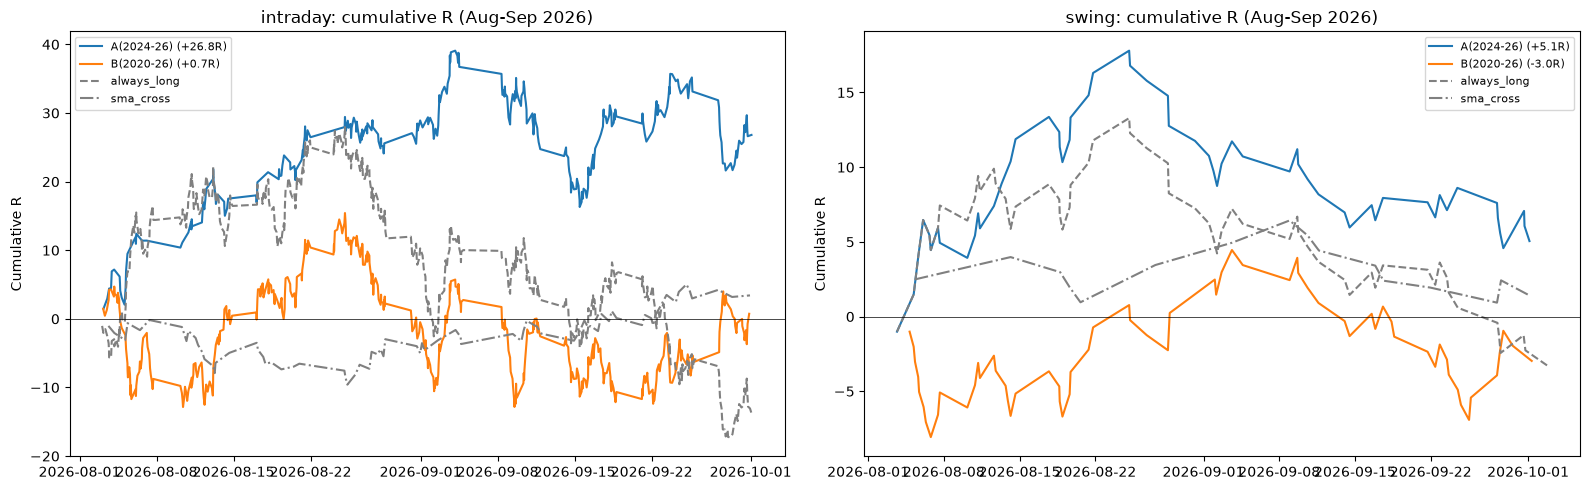

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, hzn in zip(axes, ("intraday", "swing")):
    fr_ho = FR_HO[hzn]
    ho_pos = H.holdout_rows(fr_ho)

    for exp_name, res_df, models, color in [
        ("A(2024-26)", RES_A[hzn], MODELS_A[hzn], "tab:blue"),
        ("B(2020-26)", RES_B[hzn], MODELS_B[hzn], "tab:orange"),
    ]:
        best = res_df.sort_values("total_r", ascending=False).iloc[0]
        tau, m = best["tau"], best["m"]
        boosters, cals, cols, _ = models
        raw_ho = {s: boosters[s].predict(fr_ho[cols]) for s in SIDES}
        p_ho = {s: cals[s](raw_ho[s]) for s in SIDES}
        sig = S.signals(p_ho["bull"], p_ho["bear"], tau, m)
        trades = S.run(fr_ho, ho_pos, sig[ho_pos])
        if not trades.empty:
            ax.plot(pd.to_datetime(trades["exit"]), trades["r"].cumsum(),
                    label=f"{exp_name} ({best['total_r']:+.1f}R)", color=color)

    # Baselines
    for name, style in [("always_long", "--"), ("sma_cross", "-.")]:
        sig_v = 1 if name == "always_long" else None
        if sig_v:
            trades = S.run(fr_ho, ho_pos, np.full(len(ho_pos), sig_v, dtype="int8"))
        else:
            trades = baseline_trades(fr_ho, ho_pos, "sma_cross")
        if not trades.empty:
            ax.plot(pd.to_datetime(trades["exit"]), trades["r"].cumsum(),
                    style, color="grey", label=name)

    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{hzn}: cumulative R (Aug-Sep 2026)")
    ax.legend(fontsize=8)
    ax.set_ylabel("Cumulative R")

plt.tight_layout()
plt.show()

## 10. Feature Importance (SHAP)

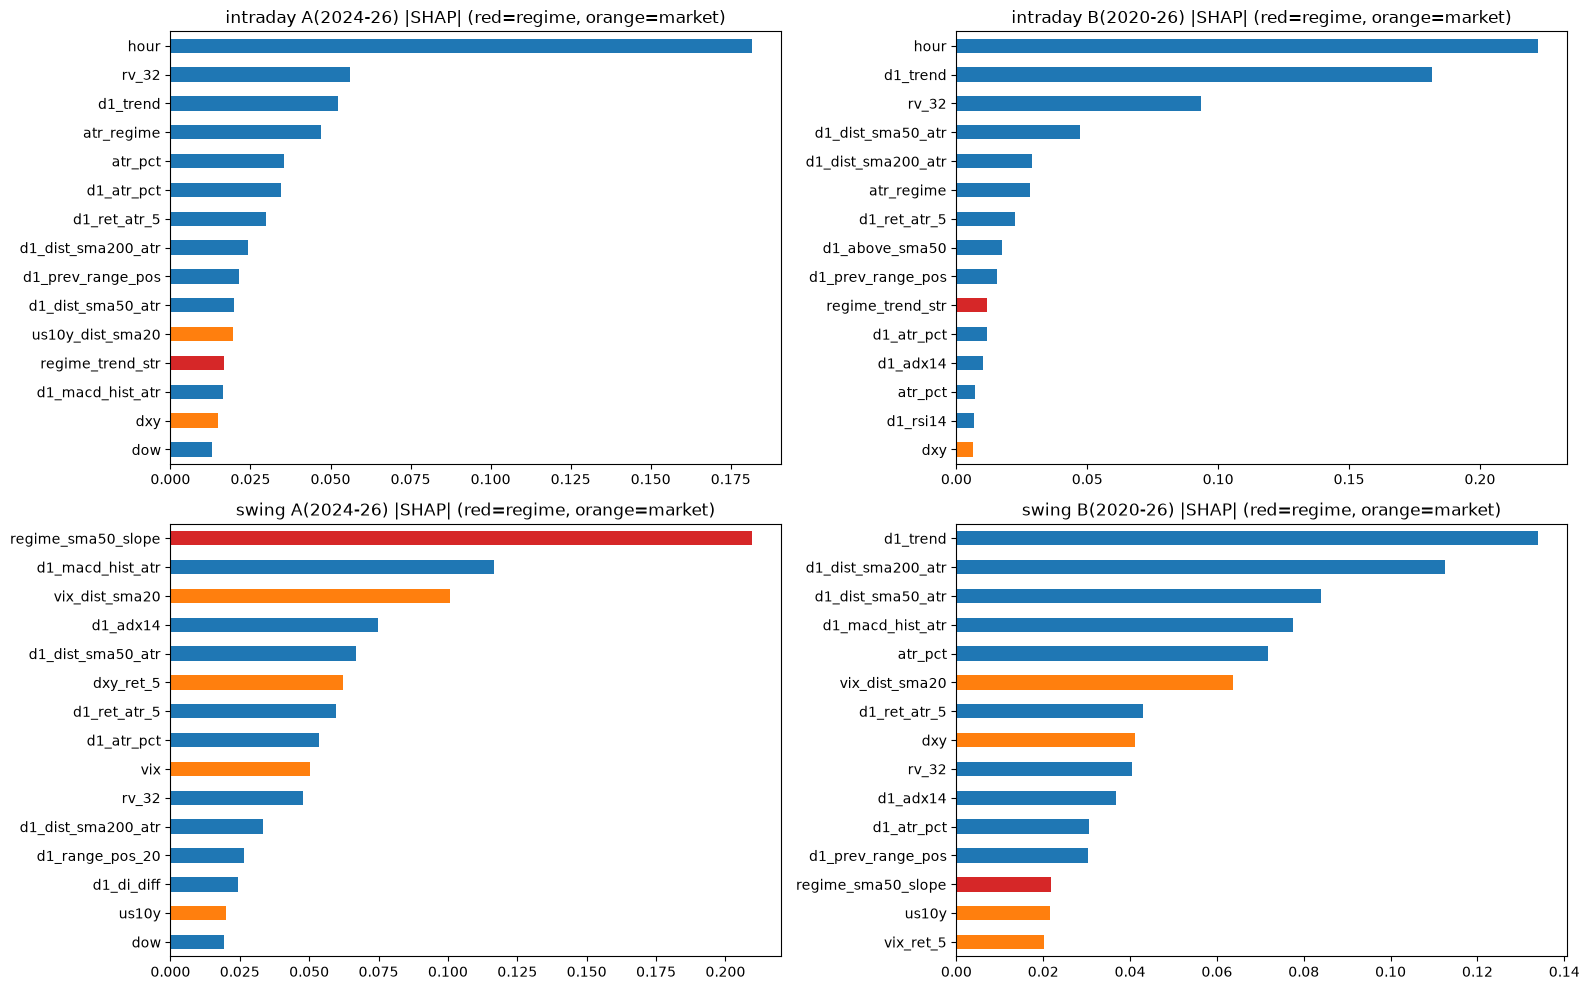

In [17]:
try:
    import shap
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for col_idx, (exp_name, models_dict, fr_dict, train_from) in enumerate([
        ("A(2024-26)", MODELS_A, FR_A, "2025-11-01"),
        ("B(2020-26)", MODELS_B, FR_B, "2025-11-01"),
    ]):
        for row_idx, hzn in enumerate(("intraday", "swing")):
            boosters, cals, cols, _ = models_dict[hzn]
            fr = fr_dict[hzn]
            recent = fr[(fr["date"] >= train_from) & usable(fr)][cols]
            X = recent.sample(min(2000, len(recent)), random_state=SEED)

            imp = pd.Series(0.0, index=cols)
            for b in boosters.values():
                sv = shap.TreeExplainer(b).shap_values(X)
                sv = np.abs(np.asarray(sv))
                imp += sv.mean(axis=tuple(i for i in range(sv.ndim) if sv.shape[i] != len(cols)))

            ax = axes[row_idx, col_idx]
            top15 = imp.sort_values(ascending=False).head(15)[::-1]
            colors = ["tab:red" if c in REGIME_COLS else
                      "tab:orange" if c in CALENDAR_COLS + MARKET_COLS else
                      "tab:blue" for c in top15.index]
            top15.plot.barh(ax=ax, color=colors)
            ax.set_title(f"{hzn} {exp_name} |SHAP| (red=regime, orange=market)")

    plt.tight_layout()
    plt.show()
except ImportError:
    print("shap not installed, skipping")

## 11. Export Winner

บันทึกโมเดลที่ดีที่สุดเป็น v0.4

In [18]:
from xau_ml import predictor as PR

# Pick the winner for each horizon
for hzn in ("intraday", "swing"):
    hz = C.HORIZONS[hzn]
    best_a = RES_A[hzn].sort_values("total_r", ascending=False).iloc[0]
    best_b = RES_B[hzn].sort_values("total_r", ascending=False).iloc[0]

    if best_a["total_r"] >= best_b["total_r"]:
        winner_name, best, models = "A(2024-26)", best_a, MODELS_A[hzn]
        train_from = "2024-01-01"
    else:
        winner_name, best, models = "B(2020-26)", best_b, MODELS_B[hzn]
        train_from = "2020-01-01"

    boosters, cals, cols, best_exp = models
    tau, m = best["tau"], best["m"]

    print(f"{hzn}: winner = {winner_name}, tau={tau:.2f}, m={m:.2f}, total_r={best['total_r']:+.1f}R")

    meta = {
        "version": VERSION,
        "symbol": C.SYMBOL,
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "horizon": hzn,
        "timeframe": hz.tf,
        "context_timeframes": list(hz.htf),
        "extras": True,
        "v3_features": True,
        "v4_features": True,
        "experiment": {"winner": winner_name, "base_exp": best_exp.id, "balanced": True,
                       "regime_cols": REGIME_COLS},
        "label": {
            "type": "triple_barrier", "entry": "open of the next bar",
            "stop_r": 1.0, "risk": f"{hz.sl_atr} x ATR14 (Wilder)",
            "tp_r": LS.tp_r, "counter_trend_tp_r": LS.ct_tp_r,
            "time_stop_bars": hz.time_stop, "intrabar_rule": "stop_first",
        },
        "features": cols,
        "feature_groups": {
            "base": [c for c in cols if c not in CALENDAR_COLS + MARKET_COLS + ["session"] + REGIME_COLS],
            "calendar": [c for c in cols if c in CALENDAR_COLS],
            "market": [c for c in cols if c in MARKET_COLS],
            "session": [c for c in cols if c == "session"],
            "regime": REGIME_COLS,
        },
        "feature_code_sha256_16": hashlib.sha256(
            (NB_DIR / "xau_ml" / "features.py").read_bytes()).hexdigest()[:16],
        "training": {
            "rows_from": train_from,
            "balanced": True,
            "scale_pos_weight": "auto (1-rate)/rate per side",
            "weights": "label uniqueness",
        },
        "model": {"params": mp.params},
        "signal_rule": {
            "tau": tau, "m": m, "no_trade": False,
            "rule": "long if p_bull>=tau and p_bull-p_bear>=m; short mirrored; else flat",
        },
        "holdout_metrics": best.to_dict(),
    }

    path = PR.save(MODEL_DIR, f"xau_{hzn}_{LS.name}", boosters, cals, meta)
    print(f"  saved: {path.relative_to(NB_DIR)}")
    print()

intraday: winner = A(2024-26), tau=0.30, m=0.05, total_r=+26.8R
  saved: models\v4\xau_intraday_ct25.json

swing: winner = A(2024-26), tau=0.20, m=0.00, total_r=+5.1R
  saved: models\v4\xau_swing_ct25.json



## Results

> **version:** `xau-bullbear-0.4.0` | **holdout:** Aug-Sep 2026

### สิ่งที่เปลี่ยนจาก v0.3
1. **Regime features** (3 ตัว): composite UP/DOWN/SIDE + trend strength + SMA50 slope
2. **Class balancing**: `scale_pos_weight = (1-rate)/rate` ต่อ side → bear model ให้ P_bear สูงพอ
3. **Exp B: training 2020-2026** (6 ปี) เห็น crash/bear/sideways/bull ครบทุก regime

### ผลลัพธ์
*(รัน notebook แล้วเติมตารางผลจริง)*